In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## attention-map

**Figure 1: Attention weights of RNNsearch-50 when it translates an English sentence into French.** Columns are the English source words and rows the generated French words; each cell is the weight α_ij that target word i gives to source word j, and each row sums to 1. The alignment is mostly monotonic, but [zone] attends to [Area] with weight 0.71, jumping over [European] and [Economic], and [économique] (0.76) and [européenne] (0.97) then look one word back at a time.

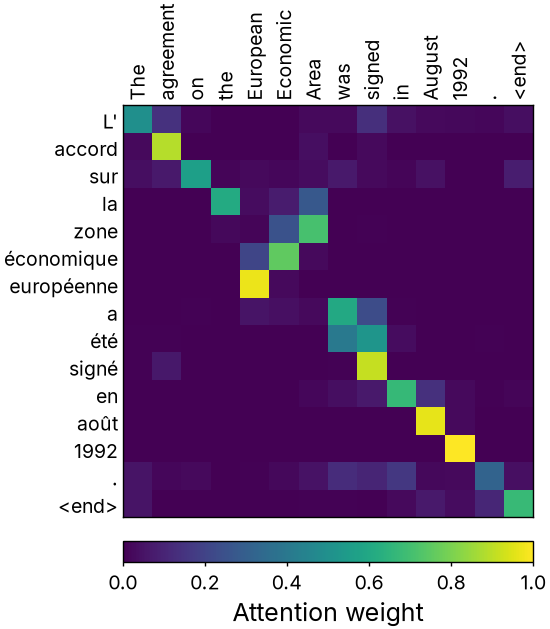

In [2]:
data = json.load(open("../data/attention-map.json"))
weights = np.array(data["weights"])

fig, ax = plt.subplots(figsize=(2.75, 2.75))
im = ax.imshow(weights, aspect="auto", vmin=0, vmax=1)
# at half width, 14 tokens only fit side by side turned 90°, with the colorbar below instead of beside the matrix
ax.set_xticks(range(len(data["source_tokens"])), labels=data["source_tokens"], rotation=90)
ax.set_yticks(range(len(data["target_tokens"])), labels=data["target_tokens"])
ax.tick_params(length=0)
ax.xaxis.tick_top()
ax.grid(False)
fig.colorbar(im, ax=ax, location="bottom", label="Attention weight")
fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/attention-map.pdf")
fig.savefig("../outputs/attention-map.png")
plt.show()